In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

In [ ]:
# 1. Load historical stock data (e.g., Apple - AAPL)
df = yf.download('AAPL', start='2020-01-01', end='2026-01-01')
data = df[['Close']].values


/tmp/ipykernel_2140/4131679669.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download('AAPL', start='2020-01-01', end='2026-01-01')
[*********************100%***********************]  1 of 1 completed


<Axes: xlabel='Date'>

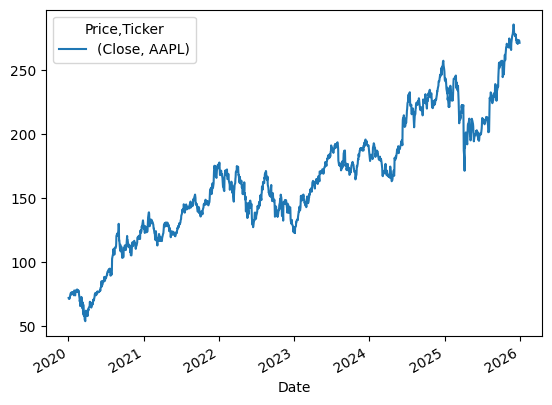

In [ ]:
df[['Close']].plot()

In [ ]:
data[:5,:]

array([[72.2166748 ],
       [71.51456451],
       [72.08444214],
       [71.74539185],
       [72.8995285 ]])

In [ ]:
# 2. Scale the data between 0 and 1
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data)

# 3. Create training sequences (look back 60 days)
def create_sequences(dataset, look_back=60):
    X, y = [], []
    for i in range(look_back, len(dataset)):
        X.append(dataset[i - look_back:i, 0])
        y.append(dataset[i, 0])
    return np.array(X), np.array(y)

In [ ]:
look_back = 60
#create your features and target (i.e., X and y)
X, y = create_sequences(scaled_data, look_back)

X.shape

(1448, 60)

In [ ]:
# Reshape X to fit LSTM input shape: [samples, time steps, features]
X = np.reshape(X, (X.shape[0], X.shape[1], 1))

# 4. Split into Train (80%) and Test (20%) sets
train_size = int(len(X) * 0.8)
X_train, y_train = X[:train_size], y[:train_size]
X_test, y_test = X[train_size:], y[train_size:]

In [ ]:
# 5. Build the LSTM model
model = Sequential([
    LSTM(50, return_sequences=True, input_shape=(X_train.shape[1], 1)),
    Dropout(0.2),
    LSTM(50, return_sequences=False),
    Dropout(0.2),
    Dense(25),
    Dense(1)
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
model.compile(optimizer='adam', loss='mean_squared_error')

# 6. Train the model - use a batch size of 32
model.fit(X_train, y_train, epochs=20, batch_size=32)

# 7. Make predictions and invert scaling
predictions = model.predict(X_test)
predictions = scaler.inverse_transform(predictions)
actual_prices = scaler.inverse_transform(y_test.reshape(-1, 1))

Epoch 1/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 6s 84ms/step - loss: 0.0214
Epoch 2/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 4s 50ms/step - loss: 0.0033
Epoch 3/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - loss: 0.0023
Epoch 4/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 3s 51ms/step - loss: 0.0019
Epoch 5/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 3s 56ms/step - loss: 0.0019
Epoch 6/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 3s 86ms/step - loss: 0.0017
Epoch 7/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 4s 50ms/step - loss: 0.0017
Epoch 8/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - loss: 0.0017
Epoch 9/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - loss: 0.0014
Epoch 10/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - loss: 0.0014
Epoch 11/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 3s 71ms/step - loss: 0.0013
Epoch 12/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 3s 73ms/step - loss: 0.0013
Epoch 13/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 4s 50ms/step - loss: 0.0012
Epoch 14/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - loss: 0.0012
Epoch 15/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 2s 58ms/step - loss: 0.0011
Epoc

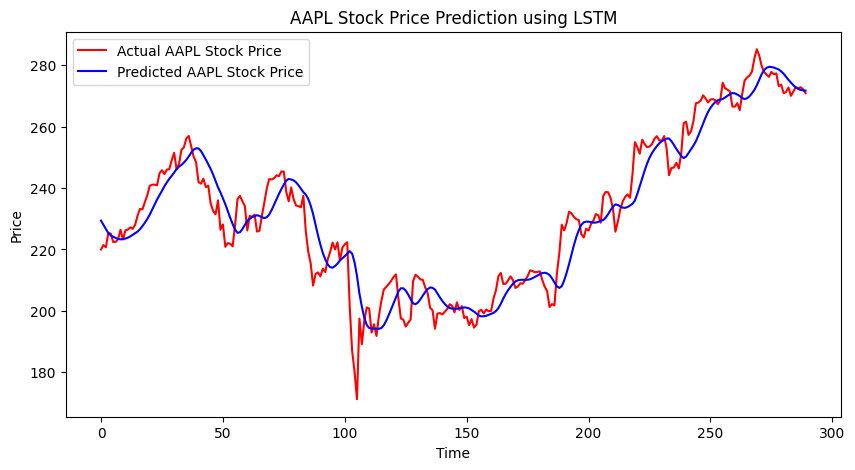

In [ ]:
# 8. Plot the results
plt.figure(figsize=(10, 5))
plt.plot(actual_prices, color='red', label=f'Actual AAPL Stock Price')
plt.plot(predictions, color='blue', label=f'Predicted AAPL Stock Price')
plt.title('AAPL Stock Price Prediction using LSTM')
plt.xlabel('Time')
plt.ylabel('Price')
plt.legend()
plt.show()